SIB - Logistic Regression
A Jupyter Notebook with examples of how to use the Logistic Regression model.

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt

from si.io.csv_file import read_csv
from si.model_selection.split import train_test_split
from si.models.logistic_regression import LogisticRegression

In [2]:
# breast-bin dataset (binary classification)
breast_dataset = read_csv('../datasets/breast_bin/breast-bin.csv', sep=',', features=True, label=True)
breast_dataset.shape()

(698, 9)

In [3]:
# the labels must be 0 or 1
breast_dataset.get_classes()

array([0., 1.])

In [4]:
# split dataset
train_dataset, test_dataset = train_test_split(breast_dataset, test_size=0.2, random_state=42)
train_dataset.shape(), test_dataset.shape()

((559, 9), (139, 9))

In [5]:
# logistic regression with the default parameters
logistic = LogisticRegression()
logistic.fit(train_dataset)
print('Iterations:', len(logistic.cost_history))
print('Score (accuracy):', logistic.score(test_dataset))
print('Cost:', logistic.cost(test_dataset))

Iterations: 1000
Score (accuracy): 0.9856115107913669
Cost: 0.27414562629966255


In [6]:
# logistic regression with a higher learning rate
logistic_fast = LogisticRegression(l2_penalty=1.0, alpha=0.1, max_iter=2000, patience=50)
logistic_fast.fit(train_dataset)
print('Iterations:', len(logistic_fast.cost_history))
print('Score (accuracy):', logistic_fast.score(test_dataset))
print('Cost:', logistic_fast.cost(test_dataset))

Iterations: 2000
Score (accuracy): 0.9856115107913669
Cost: 0.07548240505745442


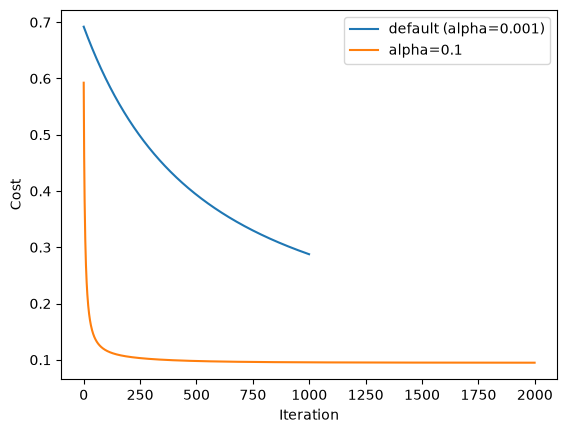

In [7]:
# cost along the iterations
plt.plot(list(logistic.cost_history.keys()), list(logistic.cost_history.values()), label='default (alpha=0.001)')
plt.plot(list(logistic_fast.cost_history.keys()), list(logistic_fast.cost_history.values()), label='alpha=0.1')
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.legend()
plt.show()

In [8]:
# extras: momentum and L1 regularization
for name, params in (('plain', {}), ('momentum 0.9', {'momentum': 0.9}), ('L1 = 5', {'l1_penalty': 5.0})):
    model = LogisticRegression(l2_penalty=0.0, alpha=0.05, max_iter=100, patience=1000, **params)
    model.fit(train_dataset)
    print(name, '| cost:', round(model.cost(train_dataset), 4), '| accuracy:', round(model.score(test_dataset), 4))

plain | cost: 0.1375 | accuracy: 0.9856
momentum 0.9 | cost: 0.0935 | accuracy: 0.9928
L1 = 5 | cost: 0.1749 | accuracy: 0.9856
